# Trabalho em Competição – Detecção de Intrusão em Redes (NSL-KDD)
Inteligência Artificial · Prof.ª Cristiane Neri Nobre

# ETAPA 1 – Análise exploratória (já entregue)

In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from google.colab import drive
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    drive.mount('/content/drive')

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)

DATA_PATH = Path("treino.csv")
TARGET_COL = None

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH, sep=None, engine="python")
    print(f"Arquivo: {DATA_PATH.resolve()}")
    print(f"Dimensões: {df.shape[0]:,} linhas × {df.shape[1]} colunas".replace(",", "."))
    display(df.head())
else:
    df = None
    print(f"Arquivo não encontrado: {DATA_PATH.resolve()} — ajuste DATA_PATH.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Arquivo: /content/treino.csv
Dimensões: 69.833 linhas × 50 colunas


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,src_bytes_kb,dst_bytes_kb,total_bytes,same_srv_pct,protocolo_cod,score_ids_legado,tipo_alerta_soc,tempo_resposta_analista_min,class
0,0,tcp,http,SF,219.0,3729,0,0,0,0,0,1.0,0.0,0.0,0.0,0,NaN,0,0.0,0,0,0,3.0,4.0,NaN,0.0,0.0,0.0,1.0,0.0,0.50,255.0,255.0,1.00,NaN,0.00,0.00,0.0,0.0,0.0,0.0,0.213867,3.641602,3948.0,100.0,0,0.176,OK,NaN,normal
1,0,tcp,finger,SF,NaN,443,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0.0,0,0.0,0,0,0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.00,223.0,NaN,0.04,0.03,0.00,0.00,0.0,0.0,0.0,0.0,NaN,0.432617,NaN,100.0,0,0.067,OK,NaN,anomaly
2,0,tcp,http,SF,162.0,29122,0,0,0,0,0,1.0,0.0,0.0,0.0,0,0.0,0,0.0,0,0,0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.00,255.0,255.0,1.00,0.00,0.00,0.00,NaN,0.0,0.0,0.0,0.158203,28.439453,29284.0,100.0,0,0.245,OK,NaN,normal
3,0,tcp,smtp,SF,942.0,332,0,0,0,0,0,1.0,0.0,0.0,0.0,0,0.0,0,0.0,0,0,0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.00,62.0,173.0,0.42,0.08,0.02,0.02,0.0,0.0,0.0,0.0,0.919922,0.324219,1274.0,100.0,0,0.239,OK,NaN,normal
4,0,tcp,http,SF,232.0,479,0,0,0,0,0,1.0,NaN,0.0,0.0,0,0.0,0,0.0,0,0,0,8.0,9.0,0.0,0.0,0.0,0.0,1.0,0.0,0.22,255.0,255.0,1.00,0.00,0.00,0.00,NaN,0.0,0.0,0.0,0.226562,0.467773,711.0,100.0,0,0.231,OK,NaN,normal


In [ ]:
if df is not None:
    display(pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "não_nulos": df.notna().sum(),
        "ausentes": df.isna().sum(),
        "distintos": df.nunique(dropna=True)
    }).sort_values(["ausentes", "distintos"], ascending=[False, True]))

    candidatos = ["classe", "class", "label", "target", "classe_alvo", "target_class", "is_anomaly", "anomalia"]
    if TARGET_COL is None:
        encontradas = [c for c in candidatos if c in df.columns]
        TARGET_COL = encontradas[0] if encontradas else None
    if TARGET_COL is None or TARGET_COL not in df.columns:
        print("Coluna-alvo não detectada. Defina TARGET_COL manualmente e execute esta célula novamente.")
        classe_eda = None
    else:
        print(f"Coluna-alvo configurada: {TARGET_COL}")
        valores = df[TARGET_COL].dropna().astype(str).str.strip().str.lower().unique().tolist()
        print("Valores distintos da classe (amostra até 30):", valores[:30])
        if any(v in {"normal", "normal.", "normal traffic", "normal_traffic"} for v in valores):
            def binarizar_classe(valor):
                if pd.isna(valor):
                    return np.nan
                s = str(valor).strip().lower()
                if s in {"normal", "normal.", "normal traffic", "normal_traffic"}:
                    return "Normal"
                return "Anomalia"
            classe_eda = df[TARGET_COL].map(binarizar_classe)
            print("A classe foi agregada em Normal vs. Anomalia: Normal mantém os rótulos normais; outros rótulos não ausentes são agregados como Anomalia.")
        else:
            classe_eda = None
            print("Não foi possível inferir com segurança a codificação binária. Configure explicitamente o mapeamento antes de calcular métricas por classe.")
else:
    classe_eda = None

,tipo,não_nulos,ausentes,distintos
tempo_resposta_analista_min,float64,6029,63804,1289
src_bytes,float64,41927,27906,2114
src_bytes_kb,float64,41927,27906,2114
total_bytes,float64,41927,27906,8484
dst_host_srv_count,float64,41989,27844,256
dst_host_serror_rate,float64,48440,21393,101
dst_host_same_src_port_rate,float64,50290,19543,101
serror_rate,float64,65099,4734,51
service,object,65417,4416,96
logged_in,float64,65583,4250,2


Coluna-alvo configurada: class
Valores distintos da classe (amostra até 30): ['normal', 'anomaly']
A classe foi agregada em Normal vs. Anomalia: Normal mantém os rótulos normais; outros rótulos não ausentes são agregados como Anomalia.


,registros,percentual
classe,,
Normal,65754,94.158922
Anomalia,4079,5.841078


Razão normal/anomalia: 16.12:1


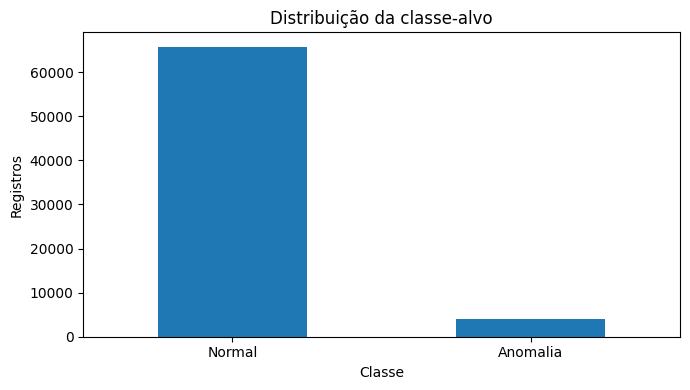

In [ ]:
if df is not None and classe_eda is not None:
    dist = classe_eda.value_counts(dropna=False).rename_axis("classe").to_frame("registros")
    dist["percentual"] = dist["registros"] / len(df) * 100
    display(dist)
    if {"Normal", "Anomalia"}.issubset(set(classe_eda.dropna().unique())):
        normais = int((classe_eda == "Normal").sum())
        anomalias = int((classe_eda == "Anomalia").sum())
        print(f"Razão normal/anomalia: {normais/anomalias:.2f}:1")
    dist_plot = classe_eda.value_counts()
    ax = dist_plot.plot(kind="bar", figsize=(7, 4), title="Distribuição da classe-alvo")
    ax.set_xlabel("Classe"); ax.set_ylabel("Registros"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
else:
    print("Etapa condicionada à configuração correta da coluna-alvo.")

In [ ]:
if df is not None:
    aus = df.isna().sum().to_frame("ausentes")
    aus["percentual_linhas"] = aus["ausentes"] / len(df) * 100
    aus = aus[aus["ausentes"] > 0].sort_values("ausentes", ascending=False)
    display(aus)
    print("Total de células ausentes:", int(df.isna().sum().sum()))
    constantes = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
    print("Atributos constantes:", constantes)
    if classe_eda is not None and "tempo_resposta_analista_min" in df.columns:
        resumo = pd.DataFrame({"classe": classe_eda, "valor": df["tempo_resposta_analista_min"]})
        out = resumo.groupby("classe", dropna=False).agg(
            total=("valor", "size"), ausentes=("valor", lambda s: int(s.isna().sum())),
            observados=("valor", lambda s: int(s.notna().sum())), mediana=("valor", "median")
        )
        out["percentual_ausente"] = out["ausentes"] / out["total"] * 100
        display(out)
else:
    print("Carregue a base para calcular ausências e constantes.")

,ausentes,percentual_linhas
tempo_resposta_analista_min,63804,91.366546
src_bytes,27906,39.961050
src_bytes_kb,27906,39.961050
total_bytes,27906,39.961050
dst_host_srv_count,27844,39.872267
dst_host_serror_rate,21393,30.634514
dst_host_same_src_port_rate,19543,27.985336
serror_rate,4734,6.779030
service,4416,6.323658
logged_in,4250,6.085948


Total de células ausentes: 292542
Atributos constantes: ['num_outbound_cmds']


,total,ausentes,observados,mediana,percentual_ausente
classe,,,,,
Anomalia,4079,960,3119,46.2,23.535180
Normal,65754,62844,2910,12.5,95.574414


In [ ]:
if df is not None:
    print("Linhas duplicadas além da primeira ocorrência:", int(df.duplicated().sum()))
    if TARGET_COL is not None and TARGET_COL in df.columns:
        preditores = [c for c in df.columns if c != TARGET_COL]
        grupos = df.groupby(preditores, dropna=False, sort=False)[TARGET_COL].nunique(dropna=False)
        grupos_conflitantes = grupos[grupos > 1]
        print("Grupos com atributos iguais e classe distinta:", int(len(grupos_conflitantes)))
        # Marca cada linha cuja assinatura de atributos aparece com mais de um rótulo.
        conflito_por_linha = df.groupby(preditores, dropna=False, sort=False)[TARGET_COL].transform(
            lambda s: s.nunique(dropna=False)
        ) > 1
        print("Linhas envolvidas nos grupos conflitantes:", int(conflito_por_linha.sum()))
        display(df.loc[conflito_por_linha].head(10))
else:
    print("Carregue a base para calcular duplicatas.")

Linhas duplicadas além da primeira ocorrência: 11355
Grupos com atributos iguais e classe distinta: 1702
Linhas envolvidas nos grupos conflitantes: 3730


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,src_bytes_kb,dst_bytes_kb,total_bytes,same_srv_pct,protocolo_cod,score_ids_legado,tipo_alerta_soc,tempo_resposta_analista_min,class
1,0,tcp,finger,SF,NaN,443,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0.0,0,0.0,0,0,0,1.0,1.0,0.0,0.00,0.0,0.0,1.00,0.00,0.00,223.0,NaN,0.04,0.03,0.0,0.00,0.0,0.00,0.00,0.00,NaN,0.432617,NaN,100.0,0,0.067,OK,NaN,anomaly
34,0,tcp,http,S0,0.0,0,0,0,0,0,0,NaN,0.0,0.0,0.0,0,0.0,0,0.0,0,0,0,298.0,49.0,1.0,0.41,0.0,0.0,0.07,0.06,0.06,255.0,NaN,0.08,0.08,0.0,0.00,NaN,1.00,0.00,0.00,0.000000,0.000000,0.0,7.0,0,0.862,ALERTA,91.2,normal
50,0,tcp,private,S0,0.0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0.0,0,0.0,0,0,0,210.0,6.0,1.0,1.00,0.0,0.0,0.03,0.06,NaN,255.0,NaN,0.02,0.06,0.0,0.00,1.0,1.00,0.00,0.00,0.000000,0.000000,0.0,3.0,0,0.886,ALERTA,68.2,normal
53,0,tcp,iso_tsap,S0,0.0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0.0,0,0.0,0,0,0,218.0,4.0,1.0,1.00,0.0,0.0,0.02,0.06,0.00,255.0,19.0,0.07,0.07,NaN,0.00,NaN,1.00,0.00,0.00,0.000000,0.000000,0.0,2.0,0,0.929,ALERTA,96.5,normal
61,0,icmp,eco_i,SF,8.0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0.0,0,0.0,0,0,0,1.0,7.0,0.0,0.00,0.0,0.0,1.00,0.00,1.00,3.0,NaN,1.00,0.00,NaN,0.26,0.0,0.00,0.00,0.00,0.007812,0.000000,8.0,100.0,2,0.678,ALERTA,22.1,anomaly
70,0,tcp,private,S0,0.0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0.0,0,0.0,0,0,0,106.0,10.0,1.0,1.00,0.0,0.0,0.09,0.05,0.00,NaN,10.0,0.04,0.04,0.0,0.00,NaN,1.00,0.00,0.00,0.000000,0.000000,0.0,9.0,0,0.843,ALERTA,82.4,anomaly
76,0,tcp,http,SF,NaN,8314,0,0,0,2,0,1.0,1.0,0.0,0.0,0,0.0,0,0.0,0,0,0,4.0,6.0,0.0,0.00,0.0,0.0,1.00,0.00,0.50,255.0,NaN,1.00,0.00,0.0,0.00,NaN,0.01,0.06,0.06,NaN,8.119141,NaN,100.0,0,0.943,ALERTA,48.6,normal
90,0,icmp,urp_i,NaN,NaN,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0.0,0,0.0,0,0,0,18.0,NaN,0.0,0.00,0.0,NaN,0.17,NaN,0.00,255.0,15.0,0.06,0.01,NaN,0.00,NaN,0.00,0.00,0.00,NaN,0.000000,NaN,17.0,2,0.000,OK,NaN,normal
93,0,tcp,http,SF,351.0,3675,0,0,0,0,0,1.0,0.0,0.0,0.0,0,0.0,0,0.0,0,0,0,17.0,17.0,0.0,0.00,0.0,0.0,1.00,0.00,0.00,255.0,NaN,1.00,0.00,0.0,0.00,0.0,0.00,0.00,0.00,0.342773,3.588867,4026.0,100.0,0,0.019,OK,NaN,anomaly
106,0,tcp,ftp_data,S0,0.0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0.0,0,0.0,0,0,0,297.0,8.0,1.0,1.00,0.0,0.0,0.03,0.05,0.00,255.0,8.0,0.03,0.05,0.0,0.00,NaN,NaN,0.00,0.00,0.000000,0.000000,0.0,3.0,0,0.943,ALERTA,64.7,normal


In [ ]:
if df is not None:
    limites = {"dst_host_count": (0, 255), "count": (0, 511), "srv_count": (0, 511)}
    resultados_limites = []
    for col, (minimo, maximo) in limites.items():
        if col in df.columns:
            x = pd.to_numeric(df[col], errors="coerce")
            invalidos = x.notna() & ((x < minimo) | (x > maximo))
            resultados_limites.append({"atributo": col, "mínimo": minimo, "máximo": maximo,
                                      "fora_da_faixa": int(invalidos.sum()), "valor_máximo": x.max()})
    display(pd.DataFrame(resultados_limites))

    taxas = ["dst_host_srv_diff_host_rate", "dst_host_srv_rerror_rate", "rerror_rate", "dst_host_same_srv_rate", "dst_host_diff_srv_rate"]
    resultados_taxas = []
    for col in taxas:
        if col in df.columns:
            x = pd.to_numeric(df[col], errors="coerce")
            m = x.notna() & ((x < 0) | (x > 1))
            resultados_taxas.append({"atributo": col, "fora_[0,1]": int(m.sum()), "mínimo": x.min(), "máximo": x.max()})
    display(pd.DataFrame(resultados_taxas))

    candidatas_negativos = ["duration", "src_bytes", "dst_bytes", "total_bytes", "src_bytes_kb", "dst_bytes_kb"]
    neg = []
    for col in candidatas_negativos:
        if col in df.columns:
            x = pd.to_numeric(df[col], errors="coerce")
            neg.append({"atributo": col, "negativos": int((x < 0).sum()), "mínimo": x.min()})
    display(pd.DataFrame(neg))

    for col, maximo in [("count", 511), ("srv_count", 511), ("dst_host_count", 255)]:
        if col in df.columns:
            x = pd.to_numeric(df[col], errors="coerce")
            fora = x[(x < 0) | (x > maximo)]
            if len(fora):
                linha = {"atributo": col, "fora_da_faixa": len(fora)}
                for fator in [10, 100, 1000, 10000]:
                    ajustado = fora / fator
                    linha[f"caber_após_dividir_por_{fator}"] = int(((ajustado >= 0) & (ajustado <= maximo)).sum())
                display(pd.DataFrame([linha]))
else:
    print("Carregue a base para avaliar os limites numéricos.")

,atributo,mínimo,máximo,fora_da_faixa,valor_máximo
0,dst_host_count,0,255,912,256000.0
1,count,0,511,464,512000.0
2,srv_count,0,511,507,512000.0


,atributo,"fora_[0,1]",mínimo,máximo
0,dst_host_srv_diff_host_rate,739,0.0,10.0
1,dst_host_srv_rerror_rate,714,0.0,10.0
2,rerror_rate,683,0.0,10.0
3,dst_host_same_srv_rate,670,0.0,10.0
4,dst_host_diff_srv_rate,623,0.0,10.0


,atributo,negativos,mínimo
0,duration,358,-1.308801e+06
1,src_bytes,189,-2.044000e+03
2,dst_bytes,0,0.000000e+00
3,total_bytes,73,-1.706000e+03
4,src_bytes_kb,189,-1.996094e+00
5,dst_bytes_kb,0,0.000000e+00


,atributo,fora_da_faixa,caber_após_dividir_por_10,caber_após_dividir_por_100,caber_após_dividir_por_1000,caber_após_dividir_por_10000
0,count,464,291,429,463,464


,atributo,fora_da_faixa,caber_após_dividir_por_10,caber_após_dividir_por_100,caber_após_dividir_por_1000,caber_após_dividir_por_10000
0,srv_count,507,317,470,506,507


,atributo,fora_da_faixa,caber_após_dividir_por_10,caber_após_dividir_por_100,caber_após_dividir_por_1000,caber_após_dividir_por_10000
0,dst_host_count,912,171,585,800,912


In [ ]:
if df is not None:
    relacoes = [
        ("src_bytes", "src_bytes_kb", "src_bytes = src_bytes_kb × 1024"),
        ("dst_bytes", "dst_bytes_kb", "dst_bytes = dst_bytes_kb × 1024")
    ]
    for original, kb, descricao in relacoes:
        if original in df.columns and kb in df.columns:
            a = pd.to_numeric(df[original], errors="coerce")
            b = pd.to_numeric(df[kb], errors="coerce")
            ok = a.notna() & b.notna()
            inconsistentes = ok & ~np.isclose(a, b * 1024, rtol=0, atol=1e-9)
            print(f"{descricao}: {int(ok.sum())} pares comparáveis; {int(inconsistentes.sum())} inconsistências")
    if all(c in df.columns for c in ["total_bytes", "src_bytes", "dst_bytes"]):
        t = pd.to_numeric(df["total_bytes"], errors="coerce")
        s = pd.to_numeric(df["src_bytes"], errors="coerce")
        d = pd.to_numeric(df["dst_bytes"], errors="coerce")
        ok = t.notna() & s.notna() & d.notna()
        inconsistentes = ok & ~np.isclose(t, s + d, rtol=0, atol=1e-9)
        print(f"total_bytes = src_bytes + dst_bytes: {int(ok.sum())} pares comparáveis; {int(inconsistentes.sum())} inconsistências")
else:
    print("Carregue a base para testar as relações entre bytes.")

src_bytes = src_bytes_kb × 1024: 41927 pares comparáveis; 0 inconsistências
dst_bytes = dst_bytes_kb × 1024: 69833 pares comparáveis; 0 inconsistências
total_bytes = src_bytes + dst_bytes: 41927 pares comparáveis; 0 inconsistências


In [ ]:
if df is not None:
    rate_cols = [c for c in df.columns if "rate" in c.lower()]
    counter_limits = {"dst_host_count": (0, 255), "count": (0, 511), "srv_count": (0, 511)}
    negative_cols = [c for c in ["duration", "src_bytes", "dst_bytes", "total_bytes", "src_bytes_kb", "dst_bytes_kb"] if c in df.columns]

    taxa_ruim = pd.Series(False, index=df.index)
    for col in rate_cols:
        x = pd.to_numeric(df[col], errors="coerce")
        taxa_ruim |= x.notna() & ((x < 0) | (x > 1))

    contador_ruim = pd.Series(False, index=df.index)
    for col, (lo, hi) in counter_limits.items():
        if col in df.columns:
            x = pd.to_numeric(df[col], errors="coerce")
            contador_ruim |= x.notna() & ((x < lo) | (x > hi))

    negativo = pd.Series(False, index=df.index)
    for col in negative_cols:
        x = pd.to_numeric(df[col], errors="coerce")
        negativo |= x.notna() & (x < 0)

    flags = pd.DataFrame({"taxas_fora_faixa": taxa_ruim, "contadores_fora_limite": contador_ruim, "valores_negativos": negativo})
    flags["numero_tipos"] = flags.sum(axis=1)
    display(flags["numero_tipos"].value_counts().sort_index().rename_axis("tipos_sinalizados").to_frame("registros"))

    if classe_eda is not None:
        resumo_classe = pd.DataFrame({"classe": classe_eda}).join(flags.drop(columns="numero_tipos"))
        linhas = []
        for classe, grupo in resumo_classe.groupby("classe", dropna=False):
            total = len(grupo)
            for nome in ["taxas_fora_faixa", "contadores_fora_limite", "valores_negativos"]:
                n = int(grupo[nome].sum())
                linhas.append({"classe": classe, "tipo": nome, "registros_sinalizados": n,
                               "total_classe": total, "percentual_na_classe": n / total * 100 if total else np.nan})
        display(pd.DataFrame(linhas))
else:
    print("Carregue a base para calcular a sobreposição entre tipos de problemas.")

,registros
tipos_sinalizados,
0,64183
1,5531
2,119


,classe,tipo,registros_sinalizados,total_classe,percentual_na_classe
0,Anomalia,taxas_fora_faixa,200,4079,4.903163
1,Anomalia,contadores_fora_limite,112,4079,2.745771
2,Anomalia,valores_negativos,28,4079,0.686443
3,Normal,taxas_fora_faixa,3168,65754,4.817958
4,Normal,contadores_fora_limite,1743,65754,2.650789
5,Normal,valores_negativos,518,65754,0.787785


In [ ]:
if df is not None:
    linhas = []
    for col in ["protocol_type", "service", "flag"]:
        if col in df.columns:
            original = df[col].dropna().astype(str)
            normalizado = original.str.strip().str.lower()
            linhas.append({"atributo": col, "níveis_originais": original.nunique(),
                           "níveis_após_strip_lower": normalizado.nunique(),
                           "exemplos_originais": ", ".join(original.drop_duplicates().head(12).tolist())})
    display(pd.DataFrame(linhas))
else:
    print("Carregue a base para inspecionar as categorias.")

,atributo,níveis_originais,níveis_após_strip_lower,exemplos_originais
0,protocol_type,6,3,"tcp, udp, icmp, TCP, ICMP, UDP"
1,service,96,67,"http, finger, smtp, domain_u, ftp_data, privat..."
2,flag,19,11,"SF, REJ, S0, sf, S1, RSTR, RSTO, S2, rej, OTH,..."


In [ ]:
if df is not None and classe_eda is not None:
    if "tipo_alerta_soc" in df.columns:
        ct = pd.crosstab(df["tipo_alerta_soc"], classe_eda, margins=True, dropna=False)
        display(ct)
        # Regra descritiva: ALERTA -> Anomalia; demais valores -> Normal, apenas para reproduzir o diagnóstico.
        pred_regra = np.where(df["tipo_alerta_soc"].astype(str).str.strip().str.upper().eq("ALERTA"), "Anomalia", "Normal")
        mask = classe_eda.notna()
        acc = (pred_regra[mask] == classe_eda[mask]).mean()
        print(f"Acurácia descritiva da regra alerta: {acc:.4%}. Não é avaliação de modelo nem deve ser interpretada como generalização.")
    if "score_ids_legado" in df.columns:
        score = pd.to_numeric(df["score_ids_legado"], errors="coerce")
        display(pd.DataFrame({"classe": classe_eda, "score": score}).groupby("classe")["score"].describe(percentiles=[.75,.95]))
    if "tempo_resposta_analista_min" in df.columns:
        tmp = pd.DataFrame({"classe": classe_eda, "tempo": pd.to_numeric(df["tempo_resposta_analista_min"], errors="coerce")})
        display(tmp.groupby("classe").agg(total=("tempo","size"), ausentes=("tempo",lambda s:int(s.isna().sum())),
                                           observados=("tempo",lambda s:int(s.notna().sum())), mediana_observada=("tempo","median")))
else:
    print("Carregue a base e configure a classe-alvo para executar a triagem de vazamento.")

class,Anomalia,Normal,All
tipo_alerta_soc,,,
ALERTA,3379,1657,5036
OK,700,64097,64797
All,4079,65754,69833


Acurácia descritiva da regra alerta: 96.6248%. Não é avaliação de modelo nem deve ser interpretada como generalização.


,count,mean,std,min,50%,75%,95%,max
classe,,,,,,,,
Anomalia,4079.0,0.706873,0.299848,0.0,0.818,0.904,1.000,1.0
Normal,65754.0,0.157998,0.174225,0.0,0.126,0.199,0.375,1.0


,total,ausentes,observados,mediana_observada
classe,,,,
Anomalia,4079,960,3119,46.2
Normal,65754,62844,2910,12.5


## Diagnóstico consolidado e decisões
Com base nos resultados observados, as recomendações são:

1. **Não treinar ainda com todos os campos.** Confirmar a proveniência de `tipo_alerta_soc`, `score_ids_legado` e `tempo_resposta_analista_min`; mantê-los fora do baseline até provar disponibilidade no instante de previsão.
2. **Auditar rótulos conflitantes.** Inspecionar os 1.702 grupos com atributos coincidentes e classes divergentes (3.730 linhas envolvidas). Não relabelar automaticamente.
3. **Não corrigir fatores de escala por palpite.** Validar os limites de `count`, `srv_count`, `dst_host_count` e das taxas com o arquivo de origem e o histórico do pipeline.
4. **Tratar ausências por mecanismo.** `src_bytes` tem 39,96% de ausência; `tempo_resposta_analista_min` tem 91,37%. Não preencher indiscriminadamente com zero ou mediana sem estudar o significado.
5. **Registrar duplicatas e evitar contaminação entre partições.** Entender o critério de duplicidade e manter grupos relacionados na mesma partição treino/validação/teste.
6. **Normalizar categorias com rastreabilidade.** Padronizar capitalização em `protocol_type` e `flag`, preservando as colunas originais; `service` não mostrou reduções por caixa.
7. **Considerar redundância funcional.** `src_bytes_kb`, `dst_bytes_kb` e `total_bytes` são matematicamente derivados dos valores em bytes e da soma; escolher conscientemente os atributos candidatos.
8. **Avaliar o desbalanceamento de maneira adequada.** Relatar matriz de confusão, precisão, recall e F1 para anomalia, F1 macro e PR-AUC; a acurácia trivial seria 94,16% sem detectar anomalias.

### Conclusão
A análise exploratória caracteriza a versão de trabalho e identifica os principais riscos para o pré-processamento e a modelagem. A conclusão é que a base pode seguir para uma preparação controlada, desde que as correções sejam documentadas e os pontos críticos — especialmente rótulos conflitantes, campos operacionais e valores fora de escala — sejam investigados antes da avaliação de modelos.

---
# ETAPA 2 – Pré-processamento (entrega 07/11)
Requisitos: tratar redundantes/inconsistentes; comparar ≥ 2 balanceamentos, 1 codificação, 1 transformação numérica e 1 redução de dimensionalidade **ou** seleção de instâncias.

| # | Responsável | Parte |
|---|---|---|
| 1 | **Izadora** | Redundantes/inconsistentes + estrutura comum de experimentos |
| 2 | **Samuel Alves** | Codificação (one-hot × ordinal × frequência, discutindo `service`) |
| 3 | **Larissa Varella**| Normalização (Standard × MinMax × log + Robust) |
| 4 | _(nome)_ | Balanceamento (sem × RandomUnderSampler × SMOTENC) |
| 5 | _(nome)_ | PCA ou seleção de instâncias + juntar a tabela final |

**Regra de ouro:** tudo que aprende algo dos dados (imputação, encoder, scaler, balanceamento, PCA) fica **dentro do Pipeline** e é ajustado só no treino de cada fold. O teste nunca participa de nenhum `fit`.

---
# ETAPA 2 – Pré-processamento (entrega 07/11)

## Divisão do trabalho

| Parte | Responsável | Conteúdo |
|---|---|---|
| **1** | **Izadora** | Redundantes/inconsistentes + estrutura comum de experimentos |
| **2** | Samuel Alves | Codificação (One-Hot × Ordinal × Frequência), com discussão de `service` |
| **3** | **Izadora** | Normalização (Standard × MinMax × Log × Robust) |
| 4 | Outro integrante | Balanceamento (sem × RandomUnderSampler × SMOTENC) |
| 5 | Outro integrante | PCA ou seleção de instâncias + tabela final |

**Atenção:** a Parte 2 foi incorporada do arquivo `02_codificacao.ipynb`. As Partes 1 e 3 permanecem separadas e identificadas conforme a divisão acima. As Partes 4 e 5 ficam preparadas para os responsáveis completarem.

**Regra contra data leakage:** imputação, codificação, normalização, balanceamento e redução/seleção são ajustados dentro do pipeline, em cada dobra de treino. O conjunto de teste não participa da validação cruzada nem da escolha do modelo.

## 0. Preparação dos dados e bibliotecas

A validação usa três dobras estratificadas e agrupadas. O número de dobras e o tamanho do Random Forest foram reduzidos em relação à versão anterior para diminuir o risco de interrupção por tempo de execução. Todas as variantes são comparadas com as mesmas divisões.

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import time
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler,
    RobustScaler, FunctionTransformer
)
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, precision_score, recall_score
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
TARGET = TARGET_COL or "class"
ID = "id"
TEST_PATH = Path("teste_sem_rotulo.csv")
if df is None:
    if not Path("treino.csv").exists():
        raise FileNotFoundError("Coloque treino.csv na pasta do notebook ou ajuste DATA_PATH na primeira célula.")
    train = pd.read_csv("treino.csv", sep=None, engine="python")
else:
    train = df.copy()

if TARGET not in train.columns:
    candidatos = ["class", "classe", "label", "target", "classe_alvo"]
    encontrados = [c for c in candidatos if c in train.columns]
    if not encontrados:
        raise ValueError("Coluna-alvo não encontrada. Ajuste TARGET_COL na primeira célula.")
    TARGET = encontrados[0]

test = pd.read_csv(TEST_PATH, sep=None, engine="python") if TEST_PATH.exists() else None

print("Treino:", train.shape)
print("Teste:", test.shape if test is not None else "não localizado (pode ser adicionado depois)")
print("Alvo:", TARGET)
print("Distribuição original:")
display(train[TARGET].value_counts(dropna=False).to_frame("registros"))

Treino: (69833, 50)
Teste: (24333, 50)
Alvo: class
Distribuição original:


,registros
class,
normal,65754
anomaly,4079


# PARTE 1 – Redundantes/inconsistentes + estrutura comum de experimentos
**Responsável: Izadora**

## 1.1 Auditoria de redundâncias e inconsistências

As verificações abaixo são condicionais: só avaliam uma relação quando todas as colunas necessárias existem. Nenhuma coluna é removida automaticamente apenas por apresentar correlação; a remoção precisa ter justificativa semântica ou matemática.

In [ ]:
def numeric_series(data, column):
    return pd.to_numeric(data[column], errors="coerce")

def audit_redundancy(data):
    checks = {}
    pairs = [
        ("src_bytes_kb", "src_bytes", lambda a, b: np.allclose(a, b / 1024, equal_nan=True)),
        ("dst_bytes_kb", "dst_bytes", lambda a, b: np.allclose(a, b / 1024, equal_nan=True)),
        ("total_bytes", None, None),
        ("same_srv_pct", "same_srv_rate", lambda a, b: np.allclose(a, 100 * b, equal_nan=True)),
    ]
    for derived, original, comparator in pairs:
        if derived == "total_bytes" and all(c in data.columns for c in ["total_bytes", "src_bytes", "dst_bytes"]):
            a = numeric_series(data, "total_bytes").to_numpy()
            b = (numeric_series(data, "src_bytes") + numeric_series(data, "dst_bytes")).to_numpy()
            checks["total_bytes = src_bytes + dst_bytes"] = bool(np.allclose(a, b, equal_nan=True))
        elif original is not None and derived in data.columns and original in data.columns:
            a = numeric_series(data, derived).to_numpy()
            b = numeric_series(data, original).to_numpy()
            checks[f"{derived} derivado de {original}"] = bool(comparator(a, b))
    if all(c in data.columns for c in ["protocol_type", "protocolo_cod"]):
        rel = data.assign(
            _protocol=data["protocol_type"].astype(str).str.strip().str.lower()
        ).groupby("_protocol")["protocolo_cod"].nunique(dropna=False)
        checks["protocolo_cod representa protocol_type 1:1"] = bool(rel.max() <= 1)
    return pd.Series(checks, name="relação_confirmada", dtype="object")

auditoria = audit_redundancy(train)
display(auditoria.to_frame())
constantes = [c for c in train.columns if c != TARGET and train[c].nunique(dropna=False) <= 1]
print("Atributos constantes:", constantes)
print("Duplicatas exatas:", int(train.duplicated().sum()))

,relação_confirmada
src_bytes_kb derivado de src_bytes,True
dst_bytes_kb derivado de dst_bytes,True
total_bytes = src_bytes + dst_bytes,True
same_srv_pct derivado de same_srv_rate,True
protocolo_cod representa protocol_type 1:1,True


Atributos constantes: ['num_outbound_cmds']
Duplicatas exatas: 11355


In [ ]:
# Verifica grupos com atributos iguais e rótulos diferentes.
feature_cols = [c for c in train.columns if c not in [TARGET, ID]]
if feature_cols:
    conflitos_por_grupo = train.groupby(feature_cols, dropna=False, sort=False)[TARGET].nunique(dropna=False)
    grupos_conflitantes = conflitos_por_grupo[conflitos_por_grupo > 1]
    print("Grupos com atributos iguais e classes diferentes:", len(grupos_conflitantes))
    print("Linhas envolvidas nesses grupos:",
          int(train.groupby(feature_cols, dropna=False, sort=False)[TARGET]
              .transform("nunique").gt(1).sum()))
else:
    print("Não há atributos disponíveis para verificar conflitos.")

Grupos com atributos iguais e classes diferentes: 1702
Linhas envolvidas nesses grupos: 3730


In [ ]:
# Diagnóstico de valores fora do domínio plausível, com contagem antes de qualquer correção.
RANGES = {
    "count": (0, 511), "srv_count": (0, 511),
    "dst_host_count": (0, 255), "dst_host_srv_count": (0, 255)
}
rate_cols = [c for c in train.columns if "rate" in c.lower()]
nonnegative_cols = [c for c in [
    "duration", "src_bytes", "dst_bytes", "total_bytes", "src_bytes_kb", "dst_bytes_kb"
] if c in train.columns]

diagnostico_faixas = []
for col, (lo, hi) in RANGES.items():
    if col in train.columns:
        x = numeric_series(train, col)
        diagnostico_faixas.append({
            "atributo": col, "fora_da_faixa": int((x.notna() & ((x < lo) | (x > hi))).sum())
        })
for col in rate_cols:
    x = numeric_series(train, col)
    diagnostico_faixas.append({
        "atributo": col, "fora_[0,1]": int((x.notna() & ((x < 0) | (x > 1))).sum())
    })
for col in nonnegative_cols:
    x = numeric_series(train, col)
    diagnostico_faixas.append({
        "atributo": col, "negativos": int((x.notna() & (x < 0)).sum())
    })
display(pd.DataFrame(diagnostico_faixas))

,atributo,fora_da_faixa,"fora_[0,1]",negativos
0,count,464.0,NaN,NaN
1,srv_count,507.0,NaN,NaN
2,dst_host_count,912.0,NaN,NaN
3,dst_host_srv_count,0.0,NaN,NaN
4,serror_rate,NaN,0.0,NaN
5,srv_serror_rate,NaN,0.0,NaN
6,rerror_rate,NaN,683.0,NaN
7,srv_rerror_rate,NaN,0.0,NaN
8,same_srv_rate,NaN,0.0,NaN
9,diff_srv_rate,NaN,0.0,NaN


## 1.2 Suspeitas de vazamento

O enunciado solicita investigar a relação de cada atributo com a classe e justificar campos removidos. A lista abaixo é uma triagem baseada no significado dos campos; confirme a disponibilidade real desses dados no momento em que uma intrusão seria prevista. O diagnóstico isolado usa somente o treino e validação cruzada agrupada.

In [ ]:
LEAK_SUSPECTS = [
    c for c in ["tipo_alerta_soc", "score_ids_legado", "tempo_resposta_analista_min"]
    if c in train.columns
]
def binary_target(series):
    values = series.astype(str).str.strip().str.lower()
    return (values != "normal").astype(int)

y_audit = binary_target(train[TARGET])
groups_audit = pd.util.hash_pandas_object(
    train[feature_cols].astype(str), index=False
).to_numpy()
cv_audit = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)

for col in LEAK_SUSPECTS:
    x = train[[col]].copy()
    if x[col].dtype == "object":
        x = pd.get_dummies(x[col].astype("string").fillna("__AUSENTE__")).astype(float)
    else:
        x[col] = pd.to_numeric(x[col], errors="coerce")
        x[col] = x[col].fillna(x[col].median())
    try:
        scores = cross_val_score(
            DecisionTreeClassifier(max_depth=2, random_state=SEED),
            x, y_audit, cv=cv_audit, groups=groups_audit,
            scoring="f1_macro", n_jobs=1
        )
        print(f"{col}: F1-macro isolado = {scores.mean():.4f} ± {scores.std():.4f}")
    except Exception as erro:
        print(f"{col}: não foi possível avaliar ({erro})")
if not LEAK_SUSPECTS:
    print("Nenhuma das colunas suspeitas listadas foi encontrada nesta versão da base.")

tipo_alerta_soc: F1-macro isolado = 0.8617 ± 0.0019
score_ids_legado: F1-macro isolado = 0.7973 ± 0.0068
tempo_resposta_analista_min: F1-macro isolado = 0.7994 ± 0.0038


## 1.3 Estratégias de limpeza

As transformações determinísticas são aplicadas igualmente ao treino e ao teste. Remoção de duplicatas e de conflitos é feita somente no treino, antes da validação, e não é aplicada ao teste porque cada linha de teste precisa gerar uma previsão.

- `norm_cat`: remove espaços nas extremidades e padroniza caixa de `protocol_type`, `service` e `flag`.
- `range_na`: transforma valores fora do domínio definido em ausentes; a imputação é aprendida no pipeline.
- `dedup`: remove duplicatas exatas do treino.
- `conflicts`: remove grupos com mesmos atributos e rótulos divergentes, sem relabelar.
- `drop`: remove colunas redundantes e, na estratégia mais conservadora, suspeitas de vazamento.

In [ ]:
REDUNDANT = [
    "src_bytes_kb", "dst_bytes_kb", "total_bytes", "same_srv_pct",
    "protocolo_cod", "num_outbound_cmds", "is_host_login"
]
RANGES = {
    "count": (0, 511), "srv_count": (0, 511),
    "dst_host_count": (0, 255), "dst_host_srv_count": (0, 255)
}
RATE_COLS = [c for c in train.columns if c.lower().endswith("_rate")]
NONNEG = [c for c in ["duration", "src_bytes", "dst_bytes"] if c in train.columns]

CLEANING = {
    "A_sem_limpeza": dict(drop=[], norm_cat=False, range_na=False, dedup=False, conflicts="keep"),
    "B_normaliza_faixa": dict(drop=[], norm_cat=True, range_na=True, dedup=False, conflicts="keep"),
    "C_B_mais_dedup": dict(drop=[], norm_cat=True, range_na=True, dedup=True, conflicts="keep"),
    "D_C_sem_conflitos": dict(drop=[], norm_cat=True, range_na=True, dedup=True, conflicts="drop"),
    "E_D_mais_redundantes": dict(drop=REDUNDANT, norm_cat=True, range_na=True, dedup=True, conflicts="drop"),
    "F_E_mais_suspeitas": dict(drop=REDUNDANT + LEAK_SUSPECTS, norm_cat=True,
                               range_na=True, dedup=True, conflicts="drop"),
}

def normalize_cats(data):
    data = data.copy()
    for col in ["protocol_type", "service", "flag"]:
        if col in data.columns:
            data[col] = data[col].astype(object).map(
                lambda v: v.strip().lower() if isinstance(v, str) else v
            )
    return data

def mask_out_of_range(data):
    data = data.copy()
    for col, (lo, hi) in RANGES.items():
        if col in data.columns:
            values = pd.to_numeric(data[col], errors="coerce")
            data.loc[(values < lo) | (values > hi), col] = np.nan
    for col in [c for c in data.columns if c.lower().endswith("_rate")]:
        values = pd.to_numeric(data[col], errors="coerce")
        data.loc[(values < 0) | (values > 1), col] = np.nan
    for col in NONNEG:
        if col in data.columns:
            values = pd.to_numeric(data[col], errors="coerce")
            data.loc[values < 0, col] = np.nan
    return data

def prepare_features(data, drop=None, norm_cat=True, range_na=True):
    data = data.copy()
    drop = drop or []
    data = data.drop(columns=[c for c in drop + [ID] if c in data.columns])
    if norm_cat:
        data = normalize_cats(data)
    if range_na:
        data = mask_out_of_range(data)
    return data

def clean_train(data, drop=None, norm_cat=True, range_na=True,
                dedup=False, conflicts="keep"):
    data = prepare_features(data, drop=drop, norm_cat=norm_cat, range_na=range_na)
    data = data.dropna(subset=[TARGET]).copy()
    features = [c for c in data.columns if c != TARGET]
    if dedup:
        data = data.drop_duplicates()
    if conflicts == "drop" and features:
        conflict_mask = data.groupby(features, dropna=False)[TARGET].transform("nunique") > 1
        data = data.loc[~conflict_mask].copy()
    return data.reset_index(drop=True)

## 1.4 Estrutura comum de experimentos

`run_experiment(...)` é a função comum para todas as partes. Cada integrante altera somente o eixo de sua responsabilidade. A validação usa `StratifiedGroupKFold`: assinaturas idênticas ficam na mesma dobra. Os passos que aprendem parâmetros ficam dentro do `imblearn.Pipeline`, portanto são ajustados somente nos dados de treino de cada dobra.

In [ ]:
class FrequencyEncoder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        X = pd.DataFrame(X).copy()
        self.cols_ = list(X.columns)
        self.maps_ = {c: X[c].value_counts(normalize=True, dropna=True) for c in self.cols_}
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.cols_)
        arrays = [
            X[c].map(self.maps_[c]).fillna(0).to_numpy(dtype=float)
            for c in self.cols_
        ]
        return np.column_stack(arrays) if arrays else np.empty((len(X), 0))

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.cols_, dtype=object)

def make_onehot(min_frequency=None):
    try:
        return OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=min_frequency,
            sparse_output=False
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=min_frequency,
            sparse=False
        )

ENCODERS = {
    "onehot": lambda: make_onehot(None),
    "onehot_rare": lambda: make_onehot(0.001),
    "ordinal": lambda: OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
    "frequency": lambda: FrequencyEncoder(),
}

In [ ]:
def signed_log1p(values):
    # Transformação logarítmica segura também para valores negativos:
    # sinal(x) * log(1 + |x|). Não descarta nem trunca observações.
    values = np.asarray(values, dtype=float)
    return np.sign(values) * np.log1p(np.abs(values))

SCALERS = {
    "standard": lambda: StandardScaler(),
    "minmax": lambda: MinMaxScaler(),
    "robust": lambda: RobustScaler(),
    "log": lambda: SkPipeline([
        ("signed_log1p", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
        ("standard", StandardScaler())
    ]),
    "nenhum": lambda: "passthrough",
}

BALANCERS = {
    "nenhum": lambda n_cat: None,
    "RUS": lambda n_cat: RandomUnderSampler(random_state=SEED),
    "SMOTE": lambda n_cat: SMOTE(random_state=SEED, k_neighbors=3),
    "SMOTENC": lambda n_cat: SMOTENC(
        categorical_features=list(range(n_cat)), random_state=SEED, k_neighbors=3
    ),
}
MODELS = {
    "DT": lambda: DecisionTreeClassifier(random_state=SEED),
    "RF": lambda: RandomForestClassifier(
        n_estimators=100, n_jobs=-1, random_state=SEED
    ),
    "LR": lambda: LogisticRegression(max_iter=1000, solver="liblinear", random_state=SEED),
}

def make_preprocessor(X, encoder="onehot", scaler="standard"):
    categorical = X.select_dtypes(exclude="number").columns.tolist()
    numeric = X.select_dtypes(include="number").columns.tolist()
    cat_pipe = SkPipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", ENCODERS[encoder]())
    ])
    num_pipe = SkPipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", SCALERS[scaler]())
    ])
    transformers = []
    if categorical:
        transformers.append(("cat", cat_pipe, categorical))
    if numeric:
        transformers.append(("num", num_pipe, numeric))
    return ColumnTransformer(transformers, remainder="drop"), len(categorical)

def build_pipeline(X, balancer="nenhum", model="RF", encoder="onehot",
                   scaler="standard", reducer=None):
    if balancer == "SMOTENC" and encoder not in ("ordinal",):
        raise ValueError("SMOTENC exige encoder='ordinal'.")
    preprocessor, n_cat = make_preprocessor(X, encoder, scaler)
    steps = [("prep", preprocessor)]
    if reducer is not None:
        steps.append(("reducer", reducer))
    bal = BALANCERS[balancer](n_cat)
    if bal is not None:
        steps.append(("balancer", bal))
    steps.append(("classifier", MODELS[model]()))
    return Pipeline(steps)

# Três dobras para reduzir o tempo de execução e evitar a interrupção observada anteriormente.
CV = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
SCORING = {
    "f1_macro": "f1_macro",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "precision_anomaly": make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall_anomaly": make_scorer(recall_score, pos_label=1, zero_division=0),
    "accuracy": "accuracy",
}
def signature_groups(X):
    return pd.util.hash_pandas_object(X.astype(str), index=False).to_numpy()

RESULTS = []
def run_experiment(df_clean, cleaning, balancer="nenhum", model="RF",
                   encoder="onehot", scaler="standard", reducer=None, tag=""):
    X = df_clean.drop(columns=[TARGET])
    y = binary_target(df_clean[TARGET])
    pipe = build_pipeline(X, balancer, model, encoder, scaler, reducer)
    start = time.time()
    scores = cross_validate(
        pipe, X, y, cv=CV, groups=signature_groups(X),
        scoring=SCORING, n_jobs=1, error_score="raise"
    )
    row = {
        "limpeza": cleaning, "codificacao": encoder, "normalizacao": scaler,
        "balanceamento": balancer,
        "reducao": tag or ("nenhuma" if reducer is None else type(reducer).__name__),
        "modelo": model, "n_linhas": len(df_clean), "tempo_s": time.time() - start
    }
    for metric in SCORING:
        values = scores[f"test_{metric}"]
        row[metric] = float(np.mean(values))
        row[metric + "_std"] = float(np.std(values, ddof=1)) if len(values) > 1 else 0.0
    RESULTS.append(row)
    return row

def export_results(path):
    pd.DataFrame(RESULTS).to_csv(path, index=False)
    print("Salvo:", path, "|", len(RESULTS), "experimentos")

## 1.5 Comparação das estratégias de limpeza

Mantemos fixos codificação, escala, balanceamento e modelo. A tabela compara progressivamente normalização de categorias, regras de faixa, remoção de duplicatas, conflitos, redundâncias e suspeitas de vazamento. Para evitar que o experimento de limpeza fique excessivamente demorado, usamos Random Forest com 100 árvores e três dobras.

In [ ]:
RESULTS = []
cleaning_rows = []
for name, config in CLEANING.items():
    cleaned = clean_train(train, **config)
    cleaning_rows.append(run_experiment(
        cleaned, name, balancer="nenhum", model="RF",
        encoder="onehot_rare", scaler="standard"
    ))

res_limpeza = pd.DataFrame(cleaning_rows).sort_values("f1_macro", ascending=False)
display(res_limpeza[[
    "limpeza", "n_linhas", "f1_macro", "f1_macro_std",
    "precision_macro", "recall_macro", "precision_anomaly",
    "recall_anomaly", "accuracy", "tempo_s"
]].round(4))
res_limpeza.to_csv("resultados_parte1_limpeza.csv", index=False)

,limpeza,n_linhas,f1_macro,f1_macro_std,precision_macro,recall_macro,precision_anomaly,recall_anomaly,accuracy,tempo_s
4,E_D_mais_redundantes,55074,0.9981,0.0004,0.9982,0.9980,0.9966,0.9962,0.9998,23.3040
3,D_C_sem_conflitos,55074,0.9979,0.0015,0.9978,0.9980,0.9957,0.9962,0.9997,23.1838
5,F_E_mais_suspeitas,55063,0.9742,0.0049,0.9934,0.9566,0.9897,0.9135,0.9968,30.1580
1,B_normaliza_faixa,69833,0.8922,0.0035,0.8791,0.9066,0.7688,0.8286,0.9754,52.0133
0,A_sem_limpeza,69833,0.8922,0.0021,0.8792,0.9064,0.7691,0.8282,0.9754,50.7631
2,C_B_mais_dedup,58478,0.8751,0.0002,0.8612,0.8905,0.7353,0.7993,0.9706,45.3811


In [ ]:
# Configuração comum para as partes seguintes.
# A limpeza F remove atributos redundantes e os campos sinalizados como possíveis vazamentos.
CLEAN_NAME = "F_E_mais_suspeitas"
CLEAN_CFG = CLEANING[CLEAN_NAME]
train_clean = clean_train(train, **CLEAN_CFG)
print("Base escolhida:", CLEAN_NAME, "| dimensões:", train_clean.shape)

Base escolhida: F_E_mais_suspeitas | dimensões: (55063, 40)


# PARTE 2 – Codificação categórica
**Responsável: Samuel Alves · conteúdo integrado de `02_codificacao.ipynb`**

Comparamos One-Hot, Ordinal e Frequency Encoding. A análise dá atenção especial a `service`, que pode apresentar alta cardinalidade. O One-Hot cria uma coluna por categoria (ou agrupa níveis raros na variante `onehot_rare`); Ordinal e Frequency mantêm uma coluna por atributo, mas comprimem a informação categórica. Todo vocabulário e frequência são aprendidos dentro da dobra de treino.

O notebook separado também descreve a comparação de imputação por moda versus categoria explícita de ausente e uma variante híbrida. Aqui preservamos o núcleo solicitado para a divisão do trabalho: One-Hot × Ordinal × Frequência, com diagnóstico de `service` e categorias desconhecidas.

In [ ]:
X_cod = train_clean.drop(columns=[TARGET])
y_cod = binary_target(train_clean[TARGET])
categorical_cols = X_cod.select_dtypes(exclude="number").columns.tolist()

diagnostico_codificacao = pd.DataFrame({
    "cardinalidade": X_cod[categorical_cols].nunique(dropna=True),
    "ausentes": X_cod[categorical_cols].isna().sum(),
    "ausentes_%": (X_cod[categorical_cols].isna().mean() * 100).round(2),
    "categorias_<0,1%": [
        int((X_cod[c].value_counts(normalize=True) < 0.001).sum())
        for c in categorical_cols
    ],
})
display(diagnostico_codificacao)

if "service" in X_cod.columns:
    service_summary = X_cod["service"].value_counts(dropna=False).head(20).rename_axis("service").to_frame("frequencia")
    display(service_summary)
    service_class = pd.crosstab(X_cod["service"], y_cod, normalize="index")
    service_class = service_class.rename(columns={0: "normal_%", 1: "anomaly_%"}) * 100
    display(service_class.sort_values("anomaly_%", ascending=False).head(15))

,cardinalidade,ausentes,ausentes_%,"categorias_<0,1%"
protocol_type,3,0,0.00,0
service,65,3493,6.34,48
flag,11,3225,5.86,4


,frequencia
service,
http,29286
domain_u,6273
smtp,4934
NaN,3493
ftp_data,3424
private,1759
other,1741
ftp,856
telnet,672


class,normal_%,anomaly_%
service,,
bgp,0.0,100.0
uucp_path,0.0,100.0
courier,0.0,100.0
csnet_ns,0.0,100.0
ctf,0.0,100.0
daytime,0.0,100.0
discard,0.0,100.0
efs,0.0,100.0
echo,0.0,100.0


In [ ]:
# Categorias novas entre treino e validação de cada dobra.
unknown_rows = []
for fold, (train_idx, valid_idx) in enumerate(
    CV.split(X_cod, y_cod, groups=signature_groups(X_cod)), start=1
):
    fold_train = X_cod.iloc[train_idx]
    fold_valid = X_cod.iloc[valid_idx]
    for col in categorical_cols:
        known = set(fold_train[col].dropna().astype(str))
        valid_levels = set(fold_valid[col].dropna().astype(str))
        new_levels = valid_levels - known
        affected = fold_valid[col].astype(str).isin(new_levels).sum()
        unknown_rows.append({
            "dobra": fold, "atributo": col,
            "categorias_novas": len(new_levels), "linhas_afetadas": int(affected)
        })
unknown_df = pd.DataFrame(unknown_rows)
display(unknown_df.groupby("atributo")[["categorias_novas", "linhas_afetadas"]].sum())

,categorias_novas,linhas_afetadas
atributo,,
flag,1,1
protocol_type,0,0
service,2,2


In [ ]:
# Comparação das variantes de codificação com o mesmo classificador e a mesma validação.
encoding_rows = []
for encoder_name in ["onehot", "onehot_rare", "ordinal", "frequency"]:
    encoding_rows.append(run_experiment(
        train_clean, CLEAN_NAME, encoder=encoder_name,
        scaler="standard", balancer="nenhum", model="LR"
    ))
res_codificacao = pd.DataFrame(encoding_rows).sort_values("f1_macro", ascending=False)
display(res_codificacao[[
    "codificacao", "f1_macro", "f1_macro_std",
    "precision_anomaly", "recall_anomaly", "tempo_s"
]].round(4))
res_codificacao.to_csv("resultados_parte2_codificacao.csv", index=False)

,codificacao,f1_macro,f1_macro_std,precision_anomaly,recall_anomaly,tempo_s
1,onehot_rare,0.9322,0.0007,0.9533,0.7975,18.7166
0,onehot,0.9305,0.0005,0.9518,0.7931,18.7934
2,ordinal,0.9073,0.0023,0.9316,0.7326,17.5584
3,frequency,0.8997,0.0055,0.9334,0.7083,17.5222


### Discussão de `service`

A cardinalidade deve ser calculada depois de `strip` e `lower`, para que variações como espaços no final não sejam contadas como serviços diferentes. O One-Hot pode aumentar a dimensionalidade, mas preserva a identidade de cada serviço; isso é importante quando categorias raras apresentam comportamento de ataque distinto. Ordinal é compacto, porém cria uma ordem numérica artificial. Frequency é compacto, mas categorias diferentes com frequências iguais ou próximas podem ficar indistinguíveis para o modelo. A conclusão deve ser preenchida com os valores gerados nas tabelas acima, sem assumir previamente qual codificação vence.

# PARTE 3 – Normalização / transformação numérica
**Responsável: Izadora**

Comparamos StandardScaler, MinMaxScaler, transformação logarítmica seguida de padronização e RobustScaler. A codificação fica fixa em `onehot_rare`, escolhida como configuração categórica de referência para reduzir o impacto de níveis muito raros de `service`. A comparação inclui Regressão Logística (sensível à escala) e Random Forest (menos sensível à escala).

A transformação `log` usa `sign(x) × log(1 + |x|)` seguida de StandardScaler. Essa forma preserva o sinal e evita erro caso apareçam valores negativos; para atributos estritamente não negativos, equivale a `log1p(x)`.

In [ ]:
normalization_rows = []
for scaler_name in ["standard", "minmax", "log", "robust"]:
    for model_name in ["LR", "RF"]:
        normalization_rows.append(run_experiment(
            train_clean, CLEAN_NAME,
            encoder="onehot_rare",
            scaler=scaler_name,
            balancer="nenhum",
            model=model_name
        ))

res_normalizacao = pd.DataFrame(normalization_rows).sort_values("f1_macro", ascending=False)
display(res_normalizacao[[
    "normalizacao", "modelo", "f1_macro", "f1_macro_std",
    "precision_macro", "recall_macro", "precision_anomaly",
    "recall_anomaly", "accuracy", "tempo_s"
]].round(4))
res_normalizacao.to_csv("resultados_parte3_normalizacao.csv", index=False)

,normalizacao,modelo,f1_macro,f1_macro_std,precision_macro,recall_macro,precision_anomaly,recall_anomaly,accuracy,tempo_s
1,standard,RF,0.9742,0.0049,0.9934,0.9566,0.9897,0.9135,0.9968,28.7934
5,log,RF,0.9741,0.0051,0.9931,0.9566,0.9891,0.9135,0.9968,29.2554
7,robust,RF,0.9739,0.0054,0.9931,0.9563,0.9891,0.9130,0.9968,29.4860
3,minmax,RF,0.9735,0.0054,0.9930,0.9555,0.9891,0.9113,0.9967,29.9828
4,log,LR,0.9379,0.0029,0.9731,0.9079,0.9524,0.8171,0.9926,18.2097
0,standard,LR,0.9322,0.0007,0.9732,0.8981,0.9533,0.7975,0.9920,19.1745
6,robust,LR,0.9304,0.0019,0.9724,0.8957,0.9518,0.7927,0.9918,37.8672
2,minmax,LR,0.9287,0.0039,0.9742,0.8916,0.9557,0.7845,0.9917,14.8450


modelo,LR,RF
normalizacao,,
log,0.9379,0.9741
minmax,0.9287,0.9735
robust,0.9304,0.9739
standard,0.9322,0.9742


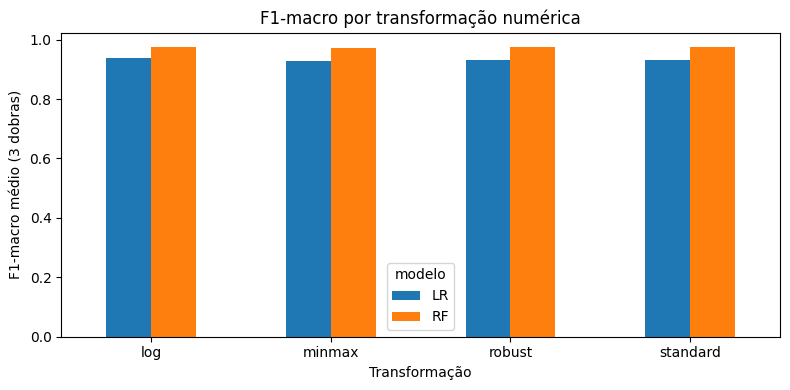

In [29]:
# Visualização comparativa do F1-macro por transformação e algoritmo.
pivot_norm = res_normalizacao.pivot(index="normalizacao", columns="modelo", values="f1_macro")
display(pivot_norm.round(4))
ax = pivot_norm.plot(kind="bar", figsize=(8, 4), title="F1-macro por transformação numérica")
ax.set_xlabel("Transformação")
ax.set_ylabel("F1-macro médio (3 dobras)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretação dos resultados da Parte 3

Na etapa de normalização, foram comparadas quatro transformações: Standard, MinMax, Robust e Log, utilizando os modelos Regressão Logística e Random Forest.

Os resultados demonstraram que o Random Forest apresentou o melhor desempenho em todas as transformações, alcançando seu maior F1-macro com a normalização Standard (0,9742). Entretanto, as diferenças entre as quatro técnicas foram muito pequenas, indicando que esse modelo possui pouca sensibilidade à escala das variáveis.

Para a Regressão Logística, a transformação Log apresentou o melhor resultado, com F1-macro de 0,9379, superando as demais técnicas. Isso sugere que a transformação logarítmica favoreceu o desempenho desse modelo.

Além disso, o Random Forest apresentou maior recall para a classe de anomalias, aproximadamente 0,9135, enquanto a Regressão Logística apresentou valores próximos de 0,80. Esse resultado demonstra uma maior capacidade do Random Forest de identificar registros anômalos.

Conclui-se que a normalização teve maior influência sobre a Regressão Logística do que sobre o Random Forest. Considerando o F1-macro e as demais métricas, o Random Forest com normalização Standard apresentou o melhor resultado geral nesta etapa.

# Parte 4 – Balanceamento de classes
**Responsável: Larissa Varella**

## 4.1 Contexto e hipótese
A classe `anomaly` é minoritária: a distribuição aproximada de 94% de `normal` e 6% de `anomaly` será conferida na base limpa antes dos experimentos. Nesse cenário, classificar tudo como `normal` pode produzir cerca de 94% de acurácia sem reconhecer nenhuma anomalia.

Comparamos três cenários sob a mesma limpeza, codificação ordinal, escala *standard* e Random Forest: nenhum balanceamento (referência), RandomUnderSampler e SMOTENC. O RUS tende a ser rápido, mas pode perder exemplos informativos da classe majoritária; o SMOTENC preserva o tratamento das variáveis categóricas, embora a geração de exemplos sintéticos possa favorecer *overfitting*. A hipótese é que o SMOTENC possa melhorar o F1-macro e o recall de `anomaly`, mas isso precisa ser verificado nas dobras, não presumido.

O balanceamento ocorre **somente no treino de cada dobra**, dentro do `imblearn.Pipeline`. Aplicá-lo antes da validação permitiria vazamento de dados.


In [30]:
# Registro da base usada na Parte 4; não aplica balanceamento nem treina modelos.
if train_clean.empty or TARGET not in train_clean.columns:
    raise ValueError("Parte 4 interrompida: train_clean está vazia ou não contém TARGET.")

y_balanceamento = binary_target(train_clean[TARGET])
if y_balanceamento.isna().any() or set(y_balanceamento.unique()) != {0, 1}:
    raise ValueError("Parte 4 interrompida: confira as duas classes de TARGET em train_clean.")

print("Base escolhida:", CLEAN_NAME, "| dimensões:", train_clean.shape)
display(pd.DataFrame({
    "classe": ["normal (0)", "anomaly (1)"],
    "quantidade": [int((y_balanceamento == 0).sum()),
                   int((y_balanceamento == 1).sum())],
    "proporcao": [float((y_balanceamento == 0).mean()),
                  float((y_balanceamento == 1).mean())],
}).round(4))

balance_rows = []  # Somente os três experimentos desta parte; RESULTS permanece intacto.


Base escolhida: F_E_mais_suspeitas | dimensões: (55063, 40)


,classe,quantidade,proporcao
0,normal (0),53246,0.967
1,anomaly (1),1817,0.033


## 4.2 Cenário inicial — sem balanceamento

Referência para medir os ganhos ou perdas dos métodos de balanceamento, mantendo fixos codificador, escala e modelo.


In [31]:
balance_rows.append(run_experiment(
    train_clean, CLEAN_NAME,
    balancer="nenhum", encoder="ordinal", scaler="standard", model="RF"
))
display(pd.DataFrame(balance_rows[-1:]).round(4))


,limpeza,codificacao,normalizacao,balanceamento,reducao,modelo,n_linhas,tempo_s,f1_macro,f1_macro_std,precision_macro,precision_macro_std,recall_macro,recall_macro_std,precision_anomaly,precision_anomaly_std,recall_anomaly,recall_anomaly_std,accuracy,accuracy_std
0,F_E_mais_suspeitas,ordinal,standard,nenhum,nenhuma,RF,55063,26.3752,0.9718,0.0045,0.9926,0.0056,0.9527,0.0035,0.9884,0.0111,0.9058,0.0067,0.9965,0.0005


## 4.3 Cenário 1 — RandomUnderSampler (undersampling)

O RandomUnderSampler remove aleatoriamente exemplos da classe **majoritária** até equilibrar as classes no conjunto de treino. É simples e rápido, mas pode descartar padrões normais importantes e causar *underfitting* ou perda de informação.


In [32]:
balance_rows.append(run_experiment(
    train_clean, CLEAN_NAME,
    balancer="RUS", encoder="ordinal", scaler="standard", model="RF"
))
display(pd.DataFrame(balance_rows[-1:]).round(4))


,limpeza,codificacao,normalizacao,balanceamento,reducao,modelo,n_linhas,tempo_s,f1_macro,f1_macro_std,precision_macro,precision_macro_std,recall_macro,recall_macro_std,precision_anomaly,precision_anomaly_std,recall_anomaly,recall_anomaly_std,accuracy,accuracy_std
0,F_E_mais_suspeitas,ordinal,standard,RUS,nenhuma,RF,55063,14.9437,0.8897,0.024,0.8303,0.032,0.9811,0.0036,0.6612,0.0639,0.9795,0.0037,0.9827,0.0037


## 4.4 Cenário 2 — SMOTENC (oversampling com categóricas)

O SMOTENC gera exemplos sintéticos da classe minoritária a partir de vizinhos, interpolando atributos numéricos e tratando separadamente os categóricos. Como outros métodos de *oversampling*, pode favorecer *overfitting*.

Aqui, `encoder="ordinal"` é obrigatório: `build_pipeline` já impede outra codificação para SMOTENC, e `make_preprocessor` posiciona as categóricas primeiro, como espera `categorical_features=range(n_cat)`.


In [33]:
# Não aplicar SMOTENC fora do pipeline nem alterar make_preprocessor.
balance_rows.append(run_experiment(
    train_clean, CLEAN_NAME,
    balancer="SMOTENC", encoder="ordinal", scaler="standard", model="RF"
))
display(pd.DataFrame(balance_rows[-1:]).round(4))


,limpeza,codificacao,normalizacao,balanceamento,reducao,modelo,n_linhas,tempo_s,f1_macro,f1_macro_std,precision_macro,precision_macro_std,recall_macro,recall_macro_std,precision_anomaly,precision_anomaly_std,recall_anomaly,recall_anomaly_std,accuracy,accuracy_std
0,F_E_mais_suspeitas,ordinal,standard,SMOTENC,nenhuma,RF,55063,47.0387,0.9731,0.0053,0.9814,0.0067,0.9652,0.0043,0.9651,0.0132,0.9315,0.0083,0.9966,0.0006


## 4.5 Tabela comparativa e exportação

A tabela destaca `balanceamento`, `f1_macro`, `f1_macro_std`, `precision_macro`, `recall_macro`, `precision_anomaly`, `recall_anomaly`, `accuracy` e `tempo_s`. Ordenamos por F1-macro. A acurácia é informativa, mas não decide a escolha: com aproximadamente 94% de exemplos normais, prever sempre `normal` já renderia cerca de 94% de acerto.


In [34]:
# Usar balance_rows, não pd.DataFrame(RESULTS): RESULTS também contém as Partes 1–3.
# O CSV mantém todas as colunas originais de run_experiment para o pd.concat final.
res_balanceamento = pd.DataFrame(balance_rows).sort_values(
    "f1_macro", ascending=False
)
display(res_balanceamento[[
    "balanceamento", "f1_macro", "f1_macro_std",
    "precision_macro", "recall_macro", "precision_anomaly",
    "recall_anomaly", "accuracy", "tempo_s"
]].round(4))
res_balanceamento.to_csv("resultados_parte4_balanceamento.csv", index=False)
print("Salvo: resultados_parte4_balanceamento.csv")


,balanceamento,f1_macro,f1_macro_std,precision_macro,recall_macro,precision_anomaly,recall_anomaly,accuracy,tempo_s
2,SMOTENC,0.9731,0.0053,0.9814,0.9652,0.9651,0.9315,0.9966,47.0387
0,nenhum,0.9718,0.0045,0.9926,0.9527,0.9884,0.9058,0.9965,26.3752
1,RUS,0.8897,0.0240,0.8303,0.9811,0.6612,0.9795,0.9827,14.9437


Salvo: resultados_parte4_balanceamento.csv


### Discussão dos resultados e encaminhamento para a Parte 5

**Como os métodos diferem.** O RUS iguala as classes removendo aleatoriamente exemplos da classe majoritária. Isso reduz o volume de treino, mas pode eliminar exemplos normais necessários para distinguir padrões difíceis, levando à perda de informação ou *underfitting*. O SMOTENC aumenta a classe minoritária com exemplos sintéticos: interpola atributos numéricos entre vizinhos e trata os categóricos como categorias, em vez de interpolar seus códigos como números contínuos. Seu risco é aprender padrões sintéticos pouco representativos ou sofrer *overfitting*. O baseline permite saber se algum balanceamento realmente ajudou.

**Como escolher.** Acurácia isolada engana: prever sempre `normal` pode alcançar cerca de 94% sem detectar `anomaly`. O **F1-macro** dá peso equivalente ao desempenho das duas classes; o **recall_macro** mostra se a sensibilidade média melhorou; e o **recall_anomaly** informa diretamente a fração de anomalias reconhecidas. Leia este último junto de `precision_anomaly`: aumentar detecções à custa de muitos falsos positivos pode não ser desejável. `f1_macro_std` mede a variabilidade do F1-macro entre as **três dobras**: um valor maior sugere desempenho menos estável, mesmo quando a média é alta. Compare as diferenças entre médias à luz dessa variação, sem tratá-la como teste de significância.

**Cuidados de implementação.** O `imblearn.Pipeline` é essencial porque o balanceador é ajustado e aplicado somente à parcela de treino de cada dobra; a parcela de validação mantém sua distribuição original. Balancear a base antes das dobras causaria *data leakage*. Para SMOTENC, `encoder="ordinal"` é obrigatório e as colunas categóricas precisam ocupar as primeiras posições após o pré-processamento; `build_pipeline` e `make_preprocessor` já asseguram essas condições. Não se deve contornar a checagem ou tentar corrigir nesta parte um eventual erro de tipos categóricos.

**Para a Parte 5.** Use a tabela para identificar o cenário que equilibra F1-macro, detecção de `anomaly`, precisão e estabilidade. Se nenhum método superar consistentemente o baseline, mantenha `nenhum`; se RUS ou SMOTENC trouxer ganho útil, leve **essa configuração explícita** como candidata à comparação com e sem redução/seleção na Parte 5. A escolha final depende dos valores obtidos na execução, não de uma vantagem presumida do balanceamento.


# Parte 5
---

PCA + juntar a tabela final

In [35]:
# Comparação sem redução e com PCA
# Manter os mesmos parâmetros nas duas execuções.

parte5_rows = []

# Referência: sem redução
parte5_rows.append(run_experiment(
    train_clean, CLEAN_NAME,
    encoder="onehot_rare",
    scaler="standard",
    balancer="nenhum",
    model="LR",
    reducer=None,
    tag="sem_reducao"
))

# Com PCA, preservando 95% da variância
parte5_rows.append(run_experiment(
    train_clean, CLEAN_NAME,
    encoder="onehot_rare",
    scaler="standard",
    balancer="nenhum",
    model="LR",
    reducer=PCA(n_components=0.95, random_state=SEED),
    tag="PCA_95"
))

res_parte5 = pd.DataFrame(parte5_rows).sort_values(
    "f1_macro", ascending=False
)

display(res_parte5[[
    "reducao", "f1_macro", "f1_macro_std",
    "precision_macro", "recall_macro",
    "precision_anomaly", "recall_anomaly",
    "accuracy", "tempo_s"
]].round(4))

res_parte5.to_csv(
    "resultados_parte5_reducao.csv",
    index=False
)

,reducao,f1_macro,f1_macro_std,precision_macro,recall_macro,precision_anomaly,recall_anomaly,accuracy,tempo_s
0,sem_reducao,0.9322,0.0007,0.9732,0.8981,0.9533,0.7975,0.9920,19.1719
1,PCA_95,0.8979,0.0021,0.9636,0.8494,0.9374,0.7004,0.9886,18.4908


In [36]:
# Consolidação dos resultados exportados por cada responsável.
from pathlib import Path
arquivos_resultados = [
    Path("resultados_parte1_limpeza.csv"),
    Path("resultados_parte2_codificacao.csv"),
    Path("resultados_parte3_normalizacao.csv"),
    Path("resultados_parte4_balanceamento.csv"),
    Path("resultados_parte5_reducao.csv"),
]
tabelas = []
for arquivo in arquivos_resultados:
    if arquivo.exists():
        tabela = pd.read_csv(arquivo)
        tabela["arquivo_origem"] = arquivo.name
        tabelas.append(tabela)

if tabelas:
    tabela_final = pd.concat(tabelas, ignore_index=True, sort=False)
    tabela_final = tabela_final.sort_values("f1_macro", ascending=False)
    display(tabela_final.round(4))
    tabela_final.to_csv("tabela_final_etapa2.csv", index=False)
    print("Tabela consolidada salva em tabela_final_etapa2.csv")
else:
    print("Execute as partes e gere os CSVs de resultados para consolidar a tabela.")

,limpeza,codificacao,normalizacao,balanceamento,reducao,modelo,n_linhas,tempo_s,f1_macro,f1_macro_std,precision_macro,precision_macro_std,recall_macro,recall_macro_std,precision_anomaly,precision_anomaly_std,recall_anomaly,recall_anomaly_std,accuracy,accuracy_std,arquivo_origem
0,E_D_mais_redundantes,onehot_rare,standard,nenhum,nenhuma,RF,55074,23.3040,0.9981,0.0004,0.9982,0.0015,0.9980,0.0008,0.9966,0.0031,0.9962,0.0018,0.9998,0.0000,resultados_parte1_limpeza.csv
1,D_C_sem_conflitos,onehot_rare,standard,nenhum,nenhuma,RF,55074,23.1838,0.9979,0.0015,0.9978,0.0020,0.9980,0.0010,0.9957,0.0040,0.9962,0.0018,0.9997,0.0002,resultados_parte1_limpeza.csv
2,F_E_mais_suspeitas,onehot_rare,standard,nenhum,nenhuma,RF,55063,30.1580,0.9742,0.0049,0.9934,0.0045,0.9566,0.0053,0.9897,0.0086,0.9135,0.0103,0.9968,0.0006,resultados_parte1_limpeza.csv
10,F_E_mais_suspeitas,onehot_rare,standard,nenhum,nenhuma,RF,55063,28.7934,0.9742,0.0049,0.9934,0.0045,0.9566,0.0053,0.9897,0.0086,0.9135,0.0103,0.9968,0.0006,resultados_parte3_normalizacao.csv
11,F_E_mais_suspeitas,onehot_rare,log,nenhum,nenhuma,RF,55063,29.2554,0.9741,0.0051,0.9931,0.0050,0.9566,0.0053,0.9891,0.0096,0.9135,0.0103,0.9968,0.0006,resultados_parte3_normalizacao.csv
12,F_E_mais_suspeitas,onehot_rare,robust,nenhum,nenhuma,RF,55063,29.4860,0.9739,0.0054,0.9931,0.0050,0.9563,0.0058,0.9891,0.0096,0.9130,0.0113,0.9968,0.0006,resultados_parte3_normalizacao.csv
13,F_E_mais_suspeitas,onehot_rare,minmax,nenhum,nenhuma,RF,55063,29.9828,0.9735,0.0054,0.9930,0.0050,0.9555,0.0058,0.9891,0.0097,0.9113,0.0113,0.9967,0.0006,resultados_parte3_normalizacao.csv
18,F_E_mais_suspeitas,ordinal,standard,SMOTENC,nenhuma,RF,55063,47.0387,0.9731,0.0053,0.9814,0.0067,0.9652,0.0043,0.9651,0.0132,0.9315,0.0083,0.9966,0.0006,resultados_parte4_balanceamento.csv
19,F_E_mais_suspeitas,ordinal,standard,nenhum,nenhuma,RF,55063,26.3752,0.9718,0.0045,0.9926,0.0056,0.9527,0.0035,0.9884,0.0111,0.9058,0.0067,0.9965,0.0005,resultados_parte4_balanceamento.csv
14,F_E_mais_suspeitas,onehot_rare,log,nenhum,nenhuma,LR,55063,18.2097,0.9379,0.0029,0.9731,0.0043,0.9079,0.0050,0.9524,0.0089,0.8171,0.0100,0.9926,0.0006,resultados_parte3_normalizacao.csv


Tabela consolidada salva em tabela_final_etapa2.csv
